# Tuning dbscan v_1 (trên `dev`)

Model: mỗi điểm GPS mang trọng số thời gian (số giây tới điểm kế tiếp), điểm được gộp vào ô lưới cạnh `cell_m`, DBSCAN chạy trên
các ô (ô là lõi khi tổng thời gian trong bán kính `eps_m` ≥ `min_time`). Mỗi cụm là một **place**. Chuỗi điểm được cắt thành
**visit**: đoạn liên tiếp cùng cụm, nối qua đoạn nhiễu ngắn hơn `bridge`, dài ≥ `T`. Toạ độ đại diện của ô ở version này: **tâm hình học của ô**.
Code: `src/geolife/clusters.py`; các phép đo dùng chung: `src/geolife/tuning.py`.
Diễn giải: [`docs/models/dbscan_v1.md`](../../../docs/models/dbscan_v1.md).

Chọn tham số của [`config.yaml`](config.yaml) theo từng bước: **định nghĩa** → **xét** → **output cho thấy** → **chọn**.
Chỉ số visit dùng đúng định nghĩa của bảng stay ([`docs/evaluation.md`](../../../docs/evaluation.md)). Chỉ chạy trên `dev`.

| Bước | Tham số |
| --- | --- |
| B1 | Khoảng ứng viên của eps |
| B2 | Lưới eps × min_time |
| B3 | min_time: chống nối chuỗi |
| B4 | eps |
| B5 | T, bridge |
| B6 | max_gap |
| B7 | cell_m |
| B8 | Khung đêm, khung hành chính |
| B9 | min_nights, min_workdays |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from geolife import io
from geolife import tuning as tu
from geolife.clusters import detect_visits
from geolife.evaluation import label_flags
from geolife.models import load_model

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "axes.titleweight": "bold"})

VERSION = 1
base = load_model("dbscan", VERSION)
P, DV = base.params, base.data_version
users = io.split_users(DV, "dev")
pts = io.load_points(DV, users=users)
flags = label_flags(pts, io.load_labels(DV))
print(f"dev: {len(users)} user, {len(pts):,} điểm, {flags.labeled.sum():,} điểm có nhãn | cell_center = {P['cell_center']}")

dev: 135 user, 18,452,398 điểm, 3,575,085 điểm có nhãn | cell_center = grid


## B1. Khoảng ứng viên của eps

**Định nghĩa:** eps là bán kính láng giềng của DBSCAN. Nó phải chứa được dao động của GPS khi user đứng yên, nếu không các ô của
cùng một chỗ không nối được với nhau.

**Xét:** EDA mục 14 (dữ liệu thô) đo bán kính chứa 90% số điểm trong 13.236 cửa sổ 10 phút đứng yên:

| Phân vị | p50 | p75 | p90 | p95 | p99 |
| --- | --- | --- | --- | --- | --- |
| Bán kính p90 (m) | 16 | 32 | 71 | 149 | 746 |

**⇒ Ứng viên:** eps ∈ {50, 100, 200, 300} m, như D của stay_point. Giá trị cụ thể chọn ở B3–B4.

## B2. Lưới eps × min_time

**Định nghĩa:** chạy mọi cặp eps ∈ {50, 100, 200, 300} m × min_time ∈ {10, 30, 60, 120, 240, 480} phút; các tham số khác giữ giá
trị trong config (T = 20 phút, bridge = 10 phút, max_gap = 24 h, cell_m = 20 m; xét lại ở B5–B7). Với mỗi cặp:
- chỉ số visit: số visit / ngày, stay giả, phân mảnh, số visit dài ≥ 6 h;
- **kích thước place**: với mỗi place có tổng thời gian visit ≥ 10 h, khoảng cách xa nhất từ một visit tới tâm của place.
  `wide_share` = % place rộng hơn 500 m, là dấu hiệu **nối chuỗi** (DBSCAN nối các ô lõi liền nhau thành một cụm kéo dài, ví dụ
  dọc đường đi làm hằng ngày, hoặc nối nhà với các chỗ lân cận).

In [2]:
grid = tu.dbscan_grid(pts, flags, P, [50, 100, 200, 300], [10, 30, 60, 120, 240, 480])
for col, fmt in [("stays_per_day", "{:.2f}"), ("long_stays", "{:,.0f}"), ("extent_p95_m", "{:,.0f}"), ("wide_share", "{:.1%}"),
                 ("fake_share", "{:.1%}"), ("fragment_share", "{:.1%}")]:
    print(col)
    display(grid.pivot(index="eps_m", columns="min_time_min", values=col).style.format(fmt))

stays_per_day


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,1.38,1.33,1.22,1.20,1.16,1.06
100,1.30,1.38,1.33,1.24,1.14,1.22
200,1.03,1.22,1.27,1.27,1.23,1.14
300,0.86,1.06,1.10,1.16,1.19,1.18


long_stays


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,"4,513","4,525","4,293","4,233","4,315","4,146"
100,"4,380","4,827","5,093","5,204","5,155","5,644"
200,"3,916","4,386","4,825","5,433","5,838","5,726"
300,"3,474","4,064","4,335","4,702","5,565","6,057"


extent_p95_m


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,"1,538",654,382,322,254,229
100,"2,444","1,299",901,585,471,436
200,"5,579","2,610","1,469","1,068",945,739
300,"7,668","3,379","2,418","1,879","1,432","1,094"


... (2 outputs left out)

fake_share


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,56.9%,57.8%,58.7%,55.9%,56.2%,55.9%
100,59.3%,57.1%,58.3%,61.1%,58.6%,63.3%
200,64.5%,60.4%,59.0%,59.9%,64.5%,63.9%
300,65.7%,64.1%,61.9%,61.4%,62.4%,64.6%


fragment_share


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,3.1%,3.1%,3.0%,3.0%,2.9%,2.8%
100,0.9%,1.2%,1.3%,1.4%,1.4%,1.6%
200,0.4%,0.5%,0.7%,0.7%,0.7%,0.8%
300,0.2%,0.3%,0.3%,0.4%,0.4%,0.4%


**Output cho thấy:**
- **Nối chuỗi rất rõ khi min_time nhỏ:** ở min_time = 10 phút, 19–46% số place rộng hơn 500 m, và place rộng nhất (p95) dài 1,5–7,7 km.
  Ô ven đường đi làm hằng ngày tích đủ thời gian để thành lõi và nối các nơi lại với nhau.
- Tăng min_time làm place gọn lại ở mọi eps (eps = 100 m: p95 từ 2.444 m xuống 436 m). eps càng lớn càng dễ nối chuỗi: ở eps = 300 m,
  kể cả min_time = 480 phút vẫn có 22,9% place rộng hơn 500 m.
- Số visit / ngày (0,86–1,39) thấp hơn hẳn stay_point, vì một chỗ chỉ thành place khi user ở đó **tổng cộng** ≥ min_time; chỗ ghé
  một lần ngắn không thành place.
- Phân mảnh rất thấp (0,2–3,1%) và giảm khi eps tăng.

⇒ Chọn min_time theo nối chuỗi (B3) trước, rồi so các eps còn lại (B4).

## B3. Chọn min_time cho từng eps: chống nối chuỗi

**Định nghĩa:** min_time càng nhỏ thì càng nhiều ô thành lõi, cụm càng dễ nối dài. Quy tắc: với mỗi eps, lấy **min_time nhỏ nhất
mà ≤ 5% số place rộng hơn 500 m** (5 lần eps = 100 m, lớn hơn một toà nhà / khu nhà). eps nào không đạt ở mọi min_time thì loại.

In [3]:
WIDE_MAX = 0.05
feas = (grid[grid.wide_share <= WIDE_MAX].sort_values("min_time_min").groupby("eps_m").head(1).set_index("eps_m")
        [["min_time_min", "stays_per_day", "fake_share", "fragment_share", "long_stays", "extent_p95_m", "wide_share"]])
display(feas.style.format({"stays_per_day": "{:.2f}", "fake_share": "{:.1%}", "fragment_share": "{:.1%}", "wide_share": "{:.1%}"}))

,min_time_min,stays_per_day,fake_share,fragment_share,long_stays,extent_p95_m,wide_share
eps_m,,,,,,,
50,60,1.22,58.7%,3.0%,4293,382.000000,3.5%
100,240,1.14,58.6%,1.4%,5155,471.000000,4.3%


**Output cho thấy:**
- eps = 50 m đạt ngưỡng từ min_time = 60 phút (3,5% place rộng); eps = 100 m từ min_time = 240 phút (4,3%).
- eps = 200 m và 300 m không đạt ở bất kỳ min_time nào (thấp nhất 12,2% và 22,9%): **loại**.

⇒ Còn hai ứng viên: (50 m, 60 phút) và (100 m, 240 phút).

## B4. Chọn eps

**Định nghĩa:** giữa các cặp (eps, min_time) còn lại sau B3, so số visit dài ≥ 6 h (thời gian ở nhà / chỗ làm nằm trong các visit
này), stay giả và phân mảnh. Quy tắc như D của stay_point: chọn eps cho **nhiều visit dài nhất**, miễn là stay giả không tăng quá
3 điểm % so với eps nhỏ nhất còn lại.

**Lưu ý về stay giả:** chỉ số đếm theo **số điểm**. Visit của DBSCAN bắt đầu ngay khi điểm vào vùng cụm, nên gồm cả đoạn xe chạy
vào / ra trong vùng đó (ghi 1–5 giây một điểm), trong khi thời gian ở yên thường nằm trong khoảng không ghi (ít điểm). Vì vậy mức
stay giả của dbscan cao hơn stay_point mà không có nghĩa là lỗi nhiều hơn: chỉ dùng để so sánh giữa các bộ tham số của dbscan.

**Xét:** bảng ở B3.

**Output cho thấy:** so với (50 m, 60 phút), cặp (100 m, 240 phút) có nhiều visit dài hơn 20% (5.155 so với 4.293), phân mảnh bằng
một nửa (1,4% so với 3,0%), và stay giả gần như bằng (58,6% so với 58,7%).

**⇒ Chọn eps = 100 m, min_time = 240 phút.** Một chỗ thành place khi user ở trong bán kính 100 m quanh nó tổng cộng ≥ 4 giờ, trên
toàn bộ dữ liệu của user.

## B5. Chọn T và bridge

**Định nghĩa:** với eps, min_time đã chọn, cắt visit theo T ∈ {10, 20, 30, 60} phút × bridge ∈ {0, 2, 10, 30} phút (phân cụm
chỉ chạy một lần vì không phụ thuộc hai tham số này).
- bridge: đoạn nhiễu (điểm ngoài mọi cụm) chen giữa ngắn hơn bridge thì nối vào visit. bridge = 0 thì một điểm GPS nhảy ra ngoài
  cụm cũng chẻ đôi visit, làm phân mảnh tăng.
- T: visit ngắn hơn T thì bỏ.

In [4]:
cut = tu.visit_cut_table(pts, flags, P, [10, 20, 30, 60], [0, 2, 10, 30])
for col, fmt in [("fragment_share", "{:.1%}"), ("stays_per_day", "{:.2f}"), ("fake_share", "{:.1%}"), ("long_stays", "{:,.0f}")]:
    print(col)
    display(cut.pivot(index="T_min", columns="bridge_min", values=col).style.format(fmt))

fragment_share


bridge_min,0,2,10,30
T_min,,,,
10,7.5%,4.0%,1.6%,1.2%
20,5.6%,3.1%,1.4%,1.1%
30,4.5%,2.7%,1.3%,0.9%
60,3.0%,1.9%,0.9%,0.7%


stays_per_day


bridge_min,0,2,10,30
T_min,,,,
10,1.47,1.39,1.36,1.36
20,1.21,1.16,1.14,1.14
30,1.10,1.07,1.05,1.05
60,0.94,0.92,0.91,0.91


fake_share


bridge_min,0,2,10,30
T_min,,,,
10,58.1%,58.5%,58.6%,58.7%
20,58.7%,58.5%,58.6%,58.5%
30,59.3%,59.0%,59.1%,59.2%
60,61.3%,60.8%,60.6%,60.7%


long_stays


bridge_min,0,2,10,30
T_min,,,,
10,"5,296","5,204","5,155","5,139"
20,"5,296","5,204","5,155","5,139"
30,"5,296","5,204","5,155","5,139"
60,"5,296","5,204","5,155","5,139"


**Output cho thấy:**
- **bridge** quyết định phân mảnh: ở T = 20, phân mảnh 5,6% (bridge = 0) → 3,1% (2 phút) → 1,4% (10 phút) → 1,1% (30 phút). Từ 0 lên
  10 phút giảm 4,2 điểm %, từ 10 lên 30 chỉ thêm 0,3 điểm % và bắt đầu nối cả những lần ra ngoài thật.
- **T** không làm giảm stay giả (58,1–59,3% ở T = 10–30, 61,3% ở T = 60), và không đổi số visit dài; T chỉ bỏ bớt visit ngắn
  (1,36 → 1,14 visit / ngày từ T = 10 lên 20).

**⇒ Chọn bridge = 10 phút; T = 20 phút**, cùng giá trị với stay_point: dữ liệu không cho lý do đổi, và giữ chung T thì hai model
cùng định nghĩa "một lần dừng có ý nghĩa".

## B6. Chọn max_gap

**Định nghĩa:** như B5 của stay_point. (a) Với mọi cặp điểm liên tiếp có khoảng không ghi ≥ 10 phút, % cặp mà điểm sau cách điểm
trước ≤ eps (user quay lại đúng chỗ cũ). (b) Chỉ số visit theo max_gap. max_gap vừa cắt visit vừa quyết định khoảng không ghi nào
được tính vào trọng số thời gian, nên mỗi giá trị phải phân cụm lại.

In [5]:
display(tu.gap_return_table(pts, P["eps_m"]).style.format({"back_share": "{:.1%}"}))
display(tu.dbscan_max_gap_table(pts, flags, P, [6, 12, 24, 48, 72])
        .style.format({"stays_per_day": "{:.2f}", "fake_share": "{:.1%}", "fragment_share": "{:.1%}"}))

,gaps,back_share
bin,,
10'-1h,14174,63.6%
1-3h,5329,45.1%
3-6h,2749,32.1%
6-12h,5149,28.1%
12-24h,4781,18.2%
24-48h,1163,11.4%
48-72h,339,10.3%
3-7 ngày,384,10.9%
> 7 ngày,307,8.8%


,n_stays,stays_per_day,fake_share,fragment_share,long_stays
max_gap_h,,,,,
6,7902,0.84,58.7%,1.3%,701
12,9548,1.02,59.5%,1.3%,3378
24,10653,1.14,58.6%,1.4%,5155
48,10914,1.17,57.9%,1.4%,5455
72,10972,1.17,57.9%,1.4%,5528


**Output cho thấy:**
- Tỉ lệ quay lại đúng chỗ (trong 100 m) giảm tới 11,4% ở 24–48 h rồi đứng yên quanh 9–11%: sau hơn một ngày, việc user ở đúng chỗ
  cũ không còn nói gì về việc user đã ở yên.
- Số visit dài bão hoà sau 24 h: 3.378 (12 h) → 5.155 (24 h, +53%) → 5.455 (48 h, chỉ +6%). Stay giả và phân mảnh gần như không đổi.

**⇒ Chọn max_gap = 24 h** (như stay_point).

## B7. Chọn cell_m

**Định nghĩa:** ô càng lớn thì càng ít ô và chạy càng nhanh, nhưng toạ độ của ô càng xa vị trí thật của các điểm. Lấy lưới mịn
10 m làm mốc, với mỗi cell_m ∈ {10, 20, 30, 50, 100} m đo: số ô / user, thời gian phân cụm, chỉ số visit, và home / office so
với mốc (% cùng place trong các user cả hai cùng dự đoán, số user chỉ một bên có dự đoán).

**Quy tắc:** chọn **cell_m lớn nhất** mà cả home và office đều trùng mốc ≥ 95% và số user chỉ một bên có dự đoán ≤ 5%.

In [6]:
ct = tu.cell_table(base, pts, flags, [10, 20, 30, 50, 100], 10)
display(ct.style.format({"stays_per_day": "{:.2f}", "fake_share": "{:.1%}", "fragment_share": "{:.1%}",
                         "home_same": "{:.1%}", "office_same": "{:.1%}"}))
ok = ((ct.home_same >= 0.95) & (ct.office_same >= 0.95)
      & (ct.home_one_side <= 0.05 * (ct.home_both + ct.home_one_side))
      & (ct.office_one_side <= 0.05 * (ct.office_both + ct.office_one_side)))
print("cell_m đạt quy tắc:", list(ct.index[ok]), "| chọn:", ct.index[ok].max(), "| config:", P["cell_m"])

,cells_per_user,cells_max,cluster_s,n_stays,stays_per_day,fake_share,fragment_share,long_stays,home_both,home_same,home_one_side,office_both,office_same,office_one_side
cell_m,,,,,,,,,,,,,,
10,12642,742512,37.200000,10879,1.16,60.1%,1.5%,5267,94,100.0%,0,80,100.0%,0
20,8149,450299,18.700000,11001,1.18,59.4%,1.7%,5284,93,97.9%,1,79,97.5%,3
30,5699,310242,13.200000,10653,1.14,58.6%,1.4%,5155,93,97.9%,1,80,97.5%,2
50,3455,185824,8.400000,10786,1.15,58.8%,1.9%,5069,93,95.7%,1,78,91.0%,5
100,1723,107516,5.100000,6745,0.72,50.5%,6.8%,1858,80,72.5%,14,57,63.2%,28


cell_m đạt quy tắc: [10, 20, 30] | chọn: 30 | config: 30


**Output cho thấy:**
- Ô 30 m giảm số ô / user từ 12.642 (ô 10 m) xuống 5.699 và thời gian phân cụm từ 37 s xuống 13 s, mà home / office vẫn trùng mốc
  97,9% / 97,5%, chỉ 1 home và 2 office có ở một bên.
- Ô 50 m bắt đầu lệch: office chỉ trùng 91,0%. Ô 100 m lớn hơn eps nên các ô gần như không còn láng giềng: số visit giảm 37%, home
  chỉ trùng 72,5%.

**⇒ Chọn cell_m = 30 m.**

## B8. Khung đêm và khung hành chính

**Định nghĩa và quy tắc chọn:** như B6 của stay_point, trên các visit. Khung đêm = giờ được ≥ 60% số visit qua đêm phủ; khung hành
chính = giờ được ≥ 40% số visit ban ngày của ngày làm việc phủ.

Visit qua đêm: 3108 visit của 77 user
Visit ban ngày, ngày làm việc: 1529 visit của 60 user


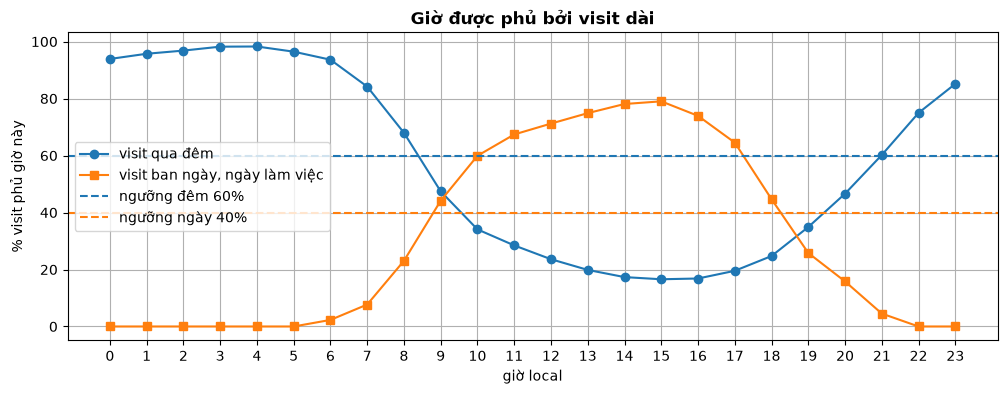

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
qua đêm,94,96,97,98,98,96,94,84,68,47,34,28,24,20,17,17,17,20,25,35,47,60,75,85
"ban ngày, ngày làm việc",0,0,0,0,0,0,2,8,23,44,60,67,71,75,78,79,74,65,45,26,16,5,0,0


Khung đêm: [21, 9] | khung hành chính: [9, 19]
Config: [21, 9] [9, 19]


In [7]:
visits = detect_visits(pts, P)
cov, counts = tu.window_coverage(visits)
for k, (ns, nu) in counts.items():
    print(f"Visit {k}: {ns} visit của {nu} user")
NIGHT_MIN, DAY_MIN = 0.6, 0.4
fig, ax = plt.subplots(figsize=(12, 4))
for c, m in zip(cov.columns, ["o-", "s-"]):
    ax.plot(cov.index, cov[c] * 100, m, label=f"visit {c}")
ax.axhline(NIGHT_MIN * 100, color="C0", ls="--", label="ngưỡng đêm 60%")
ax.axhline(DAY_MIN * 100, color="C1", ls="--", label="ngưỡng ngày 40%")
ax.set(xlabel="giờ local", ylabel="% visit phủ giờ này", xticks=range(24), title="Giờ được phủ bởi visit dài"); ax.legend(); plt.show()
display((cov.T * 100).round(0).astype(int))
night_h = [h for h in range(24) if cov["qua đêm"][h] >= NIGHT_MIN]
day_h = [h for h in range(24) if cov["ban ngày, ngày làm việc"][h] >= DAY_MIN]
print("Khung đêm:", tu.hours_to_window(night_h), "| khung hành chính:", tu.hours_to_window(day_h))
print("Config:", P["night_hours"], P["work_hours"])

**Output cho thấy:**
- Visit qua đêm phủ ≥ 60% các giờ **21:00 (60%) tới hết 08:00 (68%)**; 09:00 chỉ còn 47%.
- Visit ban ngày của ngày làm việc phủ ≥ 40% các giờ **09:00 (44%) tới hết 18:00 (45%)**; 19:00 còn 26%.
- Cả hai khung rộng hơn stay_point một giờ ([22, 9) và [9, 18)): visit của dbscan bắt đầu ngay khi user vào vùng của place nên dài
  hơn stay một chút ở hai đầu.

**⇒ Chọn:** khung đêm **[21, 9)**, mọi ngày; khung hành chính **[9, 19)**, chỉ ngày làm việc.

## B9. Cần bao nhiêu đêm / ngày làm việc?

**Định nghĩa và quy tắc chọn:** như B8 của stay_point. Với user có ≥ 20 đêm ở home (≥ 20 ngày làm việc ở office), rút ngẫu nhiên
k đêm (ngày), chọn lại home / office chỉ từ k ngày đó và so với kết quả dùng toàn bộ dữ liệu. Chọn k nhỏ nhất mà cả hai vai trò
đều trùng ≥ 60%.

In [8]:
mt = tu.min_days_agreement(base, visits, users)
display(mt.groupby(["role", "k"]).agg(users=("user", "nunique"), match=("match", "mean")).unstack("role")
        .style.format({("match", "home"): "{:.0%}", ("match", "office"): "{:.0%}"}))

**Output cho thấy:** 1 đêm đã trùng mốc 72% với home nhưng office chỉ 57%; 2 ngày: 77% home, 64% office; 3 ngày: 82% / 71%.
Home ổn định sớm hơn stay_point vì mỗi place gom cả các lần ở lại ngắn quanh nó.

**⇒ Chọn min_nights = min_workdays = 2:** mốc đầu tiên mà cả hai vai trò đều trùng ≥ 60%.

## Tổng kết

Chạy cuối cùng trên `holdout` (một lần):

```bash
uv run python -m geolife.run --model dbscan --version 1 --split holdout
```

| Tham số | Giá trị | Bước |
| --- | --- | --- |
| cell_center | grid (tâm hình học của ô) | (định nghĩa của version) |
| eps / min_time | 100 m / 240 phút | B3, B4 |
| T / bridge | 20 phút / 10 phút | B5 |
| max_gap | 24 h | B6 |
| cell_m | 30 m | B7 |
| Khung đêm / hành chính | [21, 9) / [9, 19) | B8 |
| min_nights / min_workdays | 2 / 2 | B9 |

In [9]:
print(base.params)

{'cell_center': 'grid', 'cell_m': 30, 'eps_m': 100, 'min_time_min': 240, 'T_min': 20, 'bridge_min': 10, 'max_gap_h': 24, 'night_hours': [21, 9], 'work_hours': [9, 19], 'min_nights': 2, 'min_workdays': 2, 'same_place_m': 200, 'confidence': {'n_boot': 200, 'block': 'week', 'seed': 0}}
